<a href="https://colab.research.google.com/github/layantalahmeh/machine-learning-assignment/blob/main/machine_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

GitHub Link:https://github.com/layantalahmeh/machine-learning-assignment.git

### Step 2.1: Importing Libraries

This step installs the Seaborn library and imports the necessary libraries for the machine learning project.

- `pandas`: Used to organize and manipulate data in tables.
- `numpy`: Used for numerical calculations.
- `matplotlib.pyplot`: Used to create graphs and charts.
- `seaborn`: Used to create statistical visualizations.
- `LabelEncoder`: Converts categorical data into numerical values.
- `StandardScaler`: Standardizes numerical data.
- `SelectKBest` and `f_classif`: Used to select the most relevant features for the machine learning model.

The code also sets the chart style, chart size, and table display options to make the output clearer and easier to understand.

### Step 2.2 — Load the Dataset

This cell loads the German Credit Risk dataset from a CSV file into a Pandas DataFrame.

- `DATA_PATH` stores the name of the dataset file.
- `pd.read_csv(DATA_PATH)` reads the CSV file and stores its data in the variable `dataset`.
- `dataset.shape[0]` returns the number of rows.
- `dataset.shape[1]` returns the number of columns.
- `print()` displays the dataset dimensions.

The dataset contains information about loan applicants, including age, housing, savings accounts, credit amount, loan duration, and credit risk.

In [1]:

%pip install seaborn
%matplotlib inline

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.width", 100)
pd.set_option("display.max_columns", 20)

print("All packages loaded successfully.")


All packages loaded successfully.


In [ ]:
DATA_PATH = "german_credit_data.csv"
dataset = pd.read_csv(DATA_PATH)

print(f"Dataset loaded: {dataset.shape[0]} rows, {dataset.shape[1]} columns")

Dataset loaded: 1000 rows, 10 columns


## Step 3 — Exploratory Data Analysis (EDA)

### Step 3.1 — Viewing the Data

This code displays the first five rows of the dataset to help us see the data.

In [ ]:
dataset.head()

,Age,Sex,Job,Housing,SavingAccounts,CheckingAccount,CreditAmount,Duration,Purpose,Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NaN,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad


### Dataset Shape

This code shows the number of rows and columns in the dataset.

In [ ]:
print("Shape (rows, columns):", dataset.shape)

Shape (rows, columns): (1000, 10)


### Data Types

This code shows the data type of each column in the dataset.

In [ ]:
dataset.dtypes

Age                 int64
Sex                object
Job                 int64
Housing            object
SavingAccounts     object
CheckingAccount    object
CreditAmount        int64
Duration            int64
Purpose            object
Risk               object
dtype: object

### Descriptive Statistics

This code shows basic statistics for the numerical columns in the dataset, such as the mean, standard deviation, minimum, maximum, and quartiles. It helps us understand the distribution of the data and identify its general characteristics.

In [ ]:
dataset.describe()

,Age,Job,CreditAmount,Duration
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,35.546000,1.904000,3271.258000,20.903000
std,11.375469,0.653614,2822.736876,12.058814
min,19.000000,0.000000,250.000000,4.000000
25%,27.000000,2.000000,1365.500000,12.000000
50%,33.000000,2.000000,2319.500000,18.000000
75%,42.000000,2.000000,3972.250000,24.000000
max,75.000000,3.000000,18424.000000,72.000000


### Dataset Column Names

This code displays the names of all columns in the dataset. It helps us identify the available features and understand what information each column contains.

In [ ]:
dataset.columns

Index(['Age', 'Sex', 'Job', 'Housing', 'SavingAccounts', 'CheckingAccount', 'CreditAmount',
       'Duration', 'Purpose', 'Risk'],
      dtype='object')

### Dataset Information

This code displays information about the dataset, including the number of rows and columns, column names, data types, and non-null values. It helps us understand the structure of the dataset before performing further analysis.

In [ ]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Age              1000 non-null   int64 
 1   Sex              1000 non-null   object
 2   Job              1000 non-null   int64 
 3   Housing          1000 non-null   object
 4   SavingAccounts   817 non-null    object
 5   CheckingAccount  606 non-null    object
 6   CreditAmount     1000 non-null   int64 
 7   Duration         1000 non-null   int64 
 8   Purpose          1000 non-null   object
 9   Risk             1000 non-null   object
dtypes: int64(4), object(6)
memory usage: 78.3+ KB


### Categorical Data Summary

This code summarizes the non-numerical columns in the dataset, including the number of unique values, the most frequent value, and its frequency. It helps us understand the categories and identify the most common values in the data.

In [ ]:
dataset.describe(exclude="number")

,Sex,Housing,SavingAccounts,CheckingAccount,Purpose,Risk
count,1000,1000,817,606,1000,1000
unique,2,3,4,3,8,2
top,male,own,little,little,car,good
freq,690,713,603,274,337,700


### Missing Values

This code shows the number of missing values in each column of the dataset.

In [ ]:
missing_counts = dataset.isna().sum()
print("Missing values per column:\n")
print(missing_counts)

Missing values per column:

Age                  0
Sex                  0
Job                  0
Housing              0
SavingAccounts     183
CheckingAccount    394
CreditAmount         0
Duration             0
Purpose              0
Risk                 0
dtype: int64


### Risk Distribution

This code shows the number and percentage of good and bad credit risk cases in the dataset.

In [ ]:
print(dataset["Risk"].value_counts())
print()
print(dataset["Risk"].value_counts(normalize=True).round(3) * 100, "% of total")

Risk
good    700
bad     300
Name: count, dtype: int64

Risk
good    70.0
bad     30.0
Name: proportion, dtype: float64 % of total


### Figure — Missing Values by Column

This code creates a bar chart showing the number of missing values in each column.

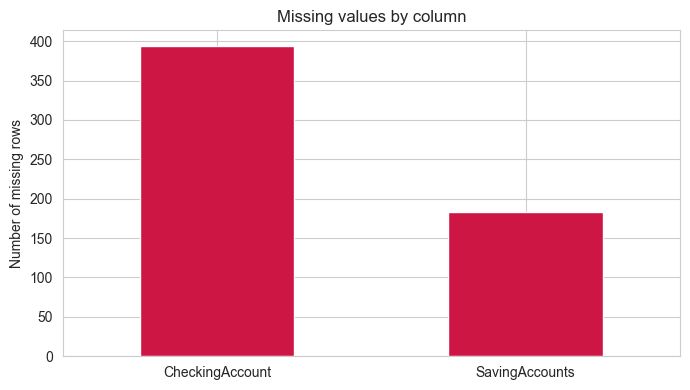

In [ ]:
missing_counts = dataset.isna().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)

plt.figure(figsize=(7, 4))
missing_counts.plot(kind="bar", color="#CE1644")
plt.title("Missing values by column")
plt.ylabel("Number of missing rows")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 3.2 Data visualization
#### Univariate plots
These plots are used to visualize and analyze one variable at a time.

### Figure — Histograms of Numeric Columns

This code creates histograms for the numerical columns to show how the data is distributed. It displays the frequency of values in each column, helping us identify common ranges, patterns, and unusual values. Each histogram represents one variable, such as Age, Job, CreditAmount, or Duration.

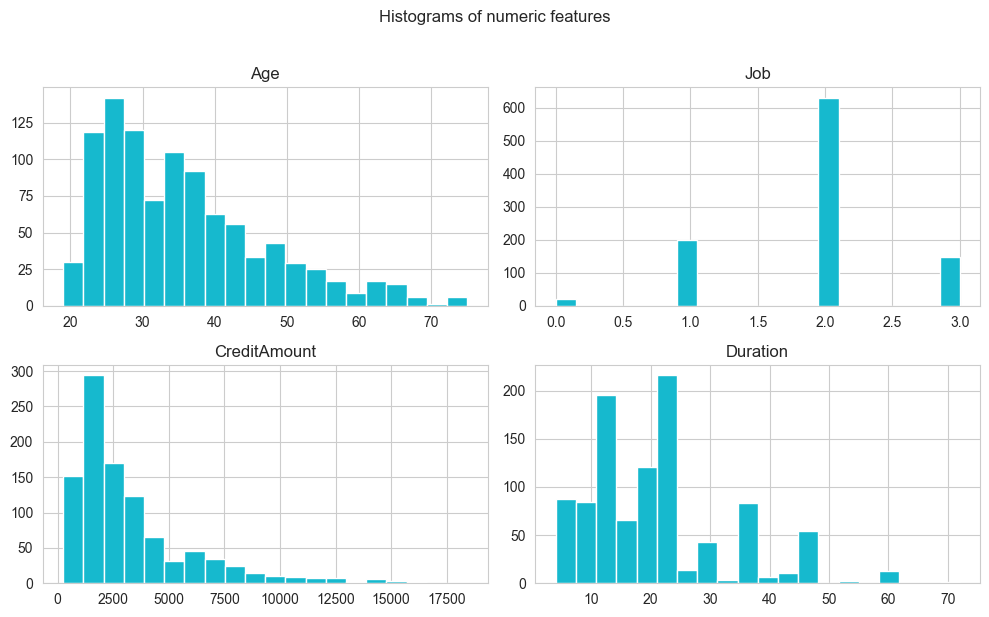

In [ ]:
numeric_cols = ["Age", "Job", "CreditAmount", "Duration"]

dataset[numeric_cols].hist(figsize=(10, 6), bins=20, color="#16B9CE", edgecolor="white")
plt.suptitle("Histograms of numeric features", y=1.02)
plt.tight_layout()
plt.show()

### Figure — Boxplots of Numeric Features

This code creates boxplots for the numerical columns to identify unusual values in the data. It helps visualize the median, spread, and overall distribution of each variable, making it easier to detect potential outliers, which are values that differ significantly from the rest of the data.

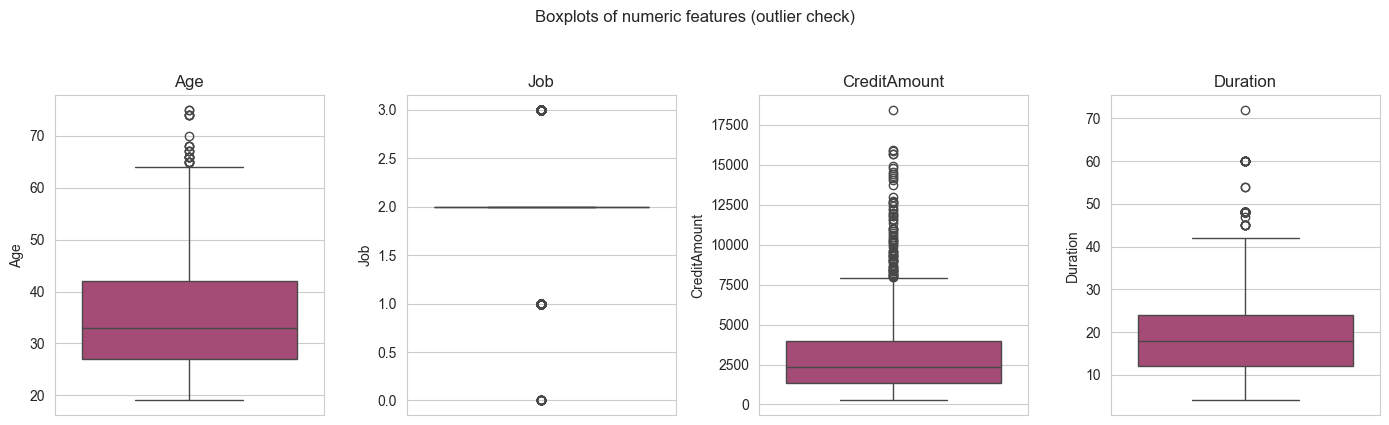

In [ ]:
fig, axes = plt.subplots(1, len(numeric_cols), figsize=(14, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(y=dataset[col], ax=ax, color="#B43D75")
    ax.set_title(col)
plt.suptitle("Boxplots of numeric features (outlier check)", y=1.05)
plt.tight_layout()
plt.show()

### Figure — Count Plots of Categorical Features

This code creates bar charts for categorical columns, such as Sex, Housing, and Risk. Each chart shows how many records belong to each category. Missing values are also included in the charts. This helps us understand the distribution of the data.

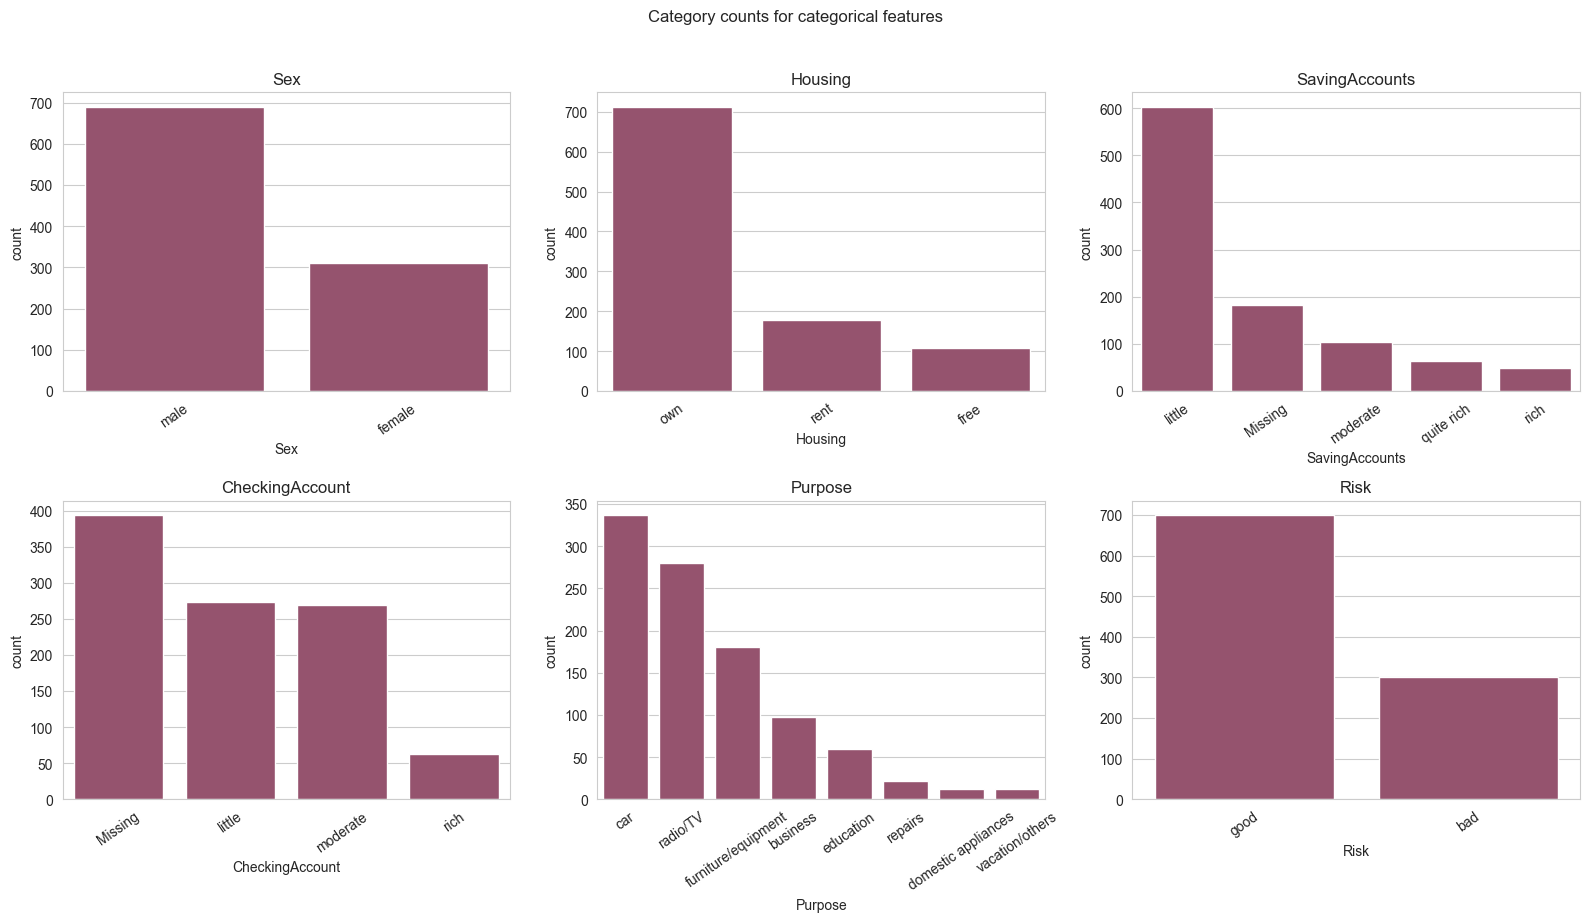

In [ ]:
categorical_cols = ["Sex", "Housing", "SavingAccounts", "CheckingAccount", "Purpose", "Risk"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for ax, col in zip(axes, categorical_cols):
    col_data = dataset[col].fillna("Missing")
    order = col_data.value_counts().index
    sns.countplot(x=col_data, order=order, ax=ax, color="#A0486C")
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=35)
plt.suptitle("Category counts for categorical features", y=1.02)
plt.tight_layout()
plt.show()

#### Multivariate plots
These plots are used to visualize and analyze the relationships between two or more variables in the dataset. They help us identify patterns, correlations, and differences between variables, providing a better understanding of how they may be related to each other.

### Figure — Correlation Matrix

This code creates a heatmap to show the correlation between numerical features. The colors and numbers help us understand whether the relationship between two features is positive, negative, or weak. Correlation values range from -1 to +1, where values closer to +1 indicate a strong positive relationship, while values closer to -1 indicate a strong negative relationship. Values near 0 indicate a weak linear relationship. This visualization helps identify patterns and understand how numerical variables are related to each other.

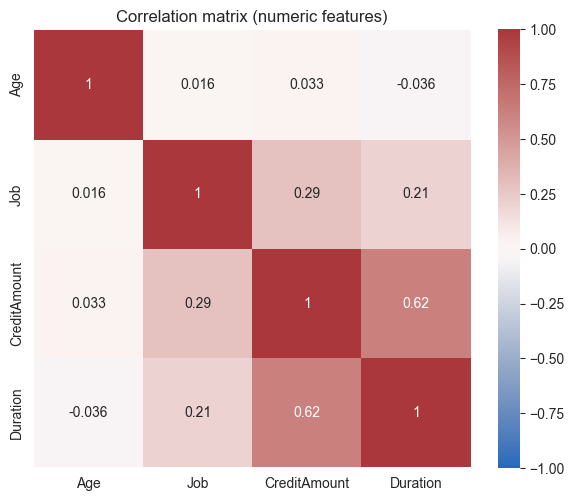

In [ ]:
plt.figure(figsize=(6, 5))
correlation = dataset[numeric_cols].corr()
sns.heatmap(correlation, vmin=-1, vmax=1, annot=True, cmap="vlag", square=True)
plt.title("Correlation matrix (numeric features)")
plt.tight_layout()
plt.show()

### Figure — Pairplot of Numeric Features

This code creates plots to show the relationships between numerical features. Different colors represent good and bad credit risk cases, helping us compare the two groups.

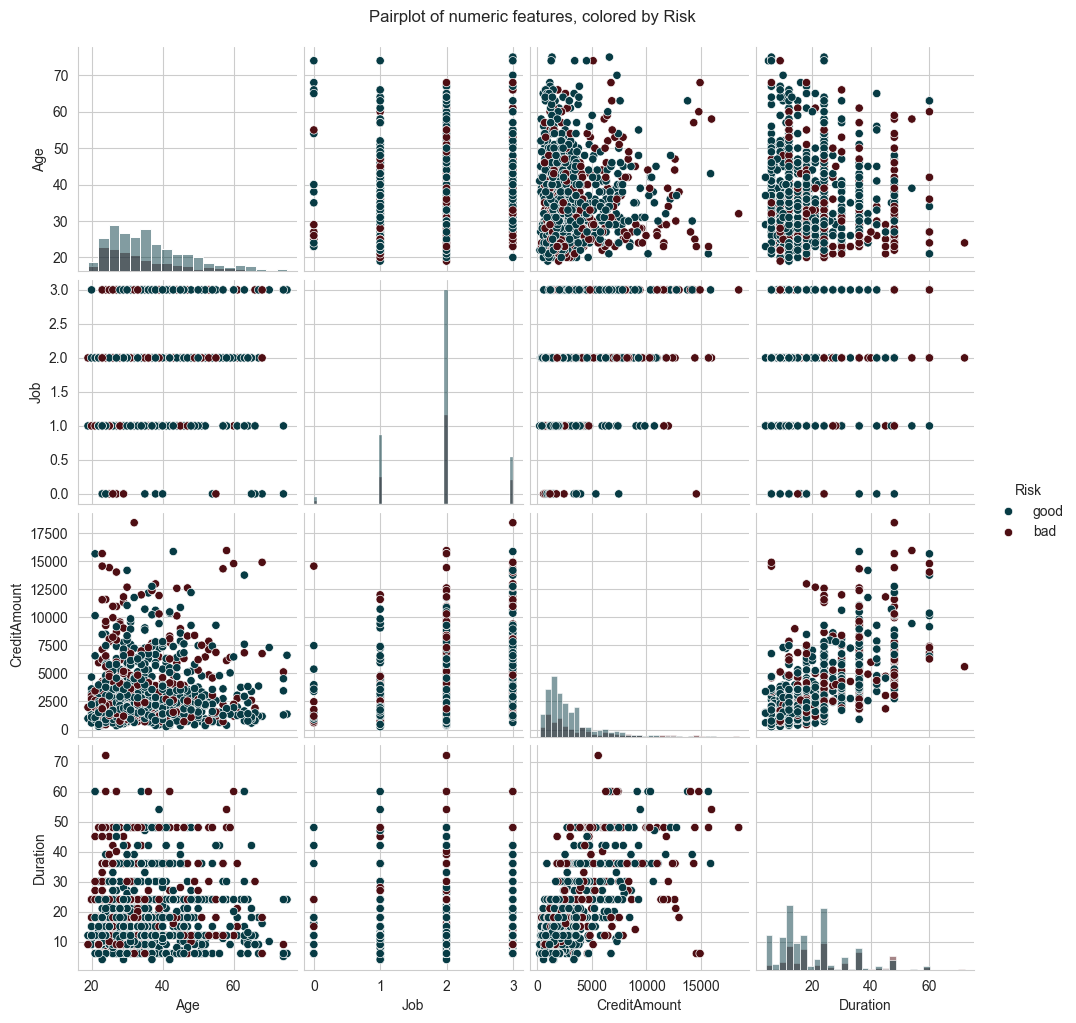

In [ ]:
sns.pairplot(dataset, vars=numeric_cols, hue="Risk", palette={"good": "#073B44", "bad": "#4E0E13"}, diag_kind="hist")
plt.suptitle("Pairplot of numeric features, colored by Risk", y=1.02)
plt.show()

### Figure — Boxplots by Credit Risk

This code creates boxplots to compare numerical features between good and bad credit risk applicants. It helps us see differences in age, job, credit amount, and loan duration between the two groups and observe possible outliers in the data. It also allows us to compare the median and spread of each feature, helping us understand how these variables differ between the two risk categories.

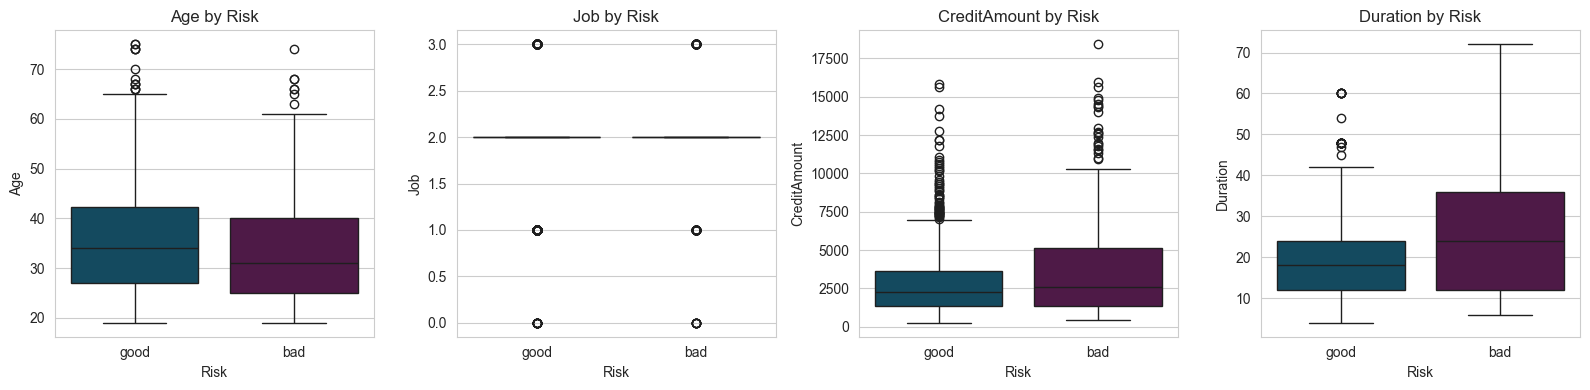

In [ ]:
fig, axes = plt.subplots(1, len(numeric_cols), figsize=(16, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(data=dataset, x="Risk", y=col, hue="Risk",
                palette={"good": "#084F6B", "bad": "#57114D"}, legend=False, ax=ax)
    ax.set_title(f"{col} by Risk")
plt.tight_layout()
plt.show()

## Step 4 — Data Preparation

### 4.1 Data cleaning — handling missing values
This code creates a copy of the dataset and replaces missing values in the SavingAccounts and CheckingAccount columns with "none". It then checks if any missing values remain.

In [ ]:
df_clean = dataset.copy()
df_clean["SavingAccounts"] = df_clean["SavingAccounts"].fillna("none")
df_clean["CheckingAccount"] = df_clean["CheckingAccount"].fillna("none")
print("Remaining missing values:\n")
print(df_clean.isna().sum())

Remaining missing values:

Age                0
Sex                0
Job                0
Housing            0
SavingAccounts     0
CheckingAccount    0
CreditAmount       0
Duration           0
Purpose            0
Risk               0
dtype: int64


### 4.2 Data transformation

### Step — Encoding Categorical Data
This code converts categorical values into numbers using LabelEncoder. It saves the encoders so the original categories can be identified later, and prints the numerical encoding for each category.

In [ ]:
df_encoded = df_clean.copy()
categorical_cols_all = ["Sex", "Housing", "SavingAccounts", "CheckingAccount", "Purpose", "Risk"]

encoders = {}
for col in categorical_cols_all:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_clean[col])
    encoders[col] = le
    print(f"{col:16s} -> {list(le.classes_)}")

Sex              -> ['female', 'male']
Housing          -> ['free', 'own', 'rent']
SavingAccounts   -> ['little', 'moderate', 'none', 'quite rich', 'rich']
CheckingAccount  -> ['little', 'moderate', 'none', 'rich']
Purpose          -> ['business', 'car', 'domestic appliances', 'education', 'furniture/equipment', 'radio/TV', 'repairs', 'vacation/others']
Risk             -> ['bad', 'good']


### Step — Scaling Numeric Features

This code standardizes the numerical columns and compares the first three rows before and after scaling. The scaled values have a mean close to 0 and a standard deviation close to 1.

In [ ]:
scaler = StandardScaler()
numeric_cols_to_scale = ["Age", "Job", "CreditAmount", "Duration"]

df_scaled = df_encoded.copy()
df_scaled[numeric_cols_to_scale] = scaler.fit_transform(df_encoded[numeric_cols_to_scale])

print("Before scaling:")
print(df_encoded[numeric_cols_to_scale].head(3))
print("\nAfter scaling (mean ~0, std ~1):")
print(df_scaled[numeric_cols_to_scale].head(3).round(3))

Before scaling:
   Age  Job  CreditAmount  Duration
0   67    2          1169         6
1   22    2          5951        48
2   49    1          2096        12

After scaling (mean ~0, std ~1):
     Age    Job  CreditAmount  Duration
0  2.766  0.147        -0.745    -1.236
1 -1.191  0.147         0.950     2.248
2  1.183 -1.384        -0.417    -0.739


### Figure — Credit Amount Before and After Scaling

This code creates two histograms to compare CreditAmount before and after scaling. It shows how scaling changes the values while keeping the distribution shape similar.

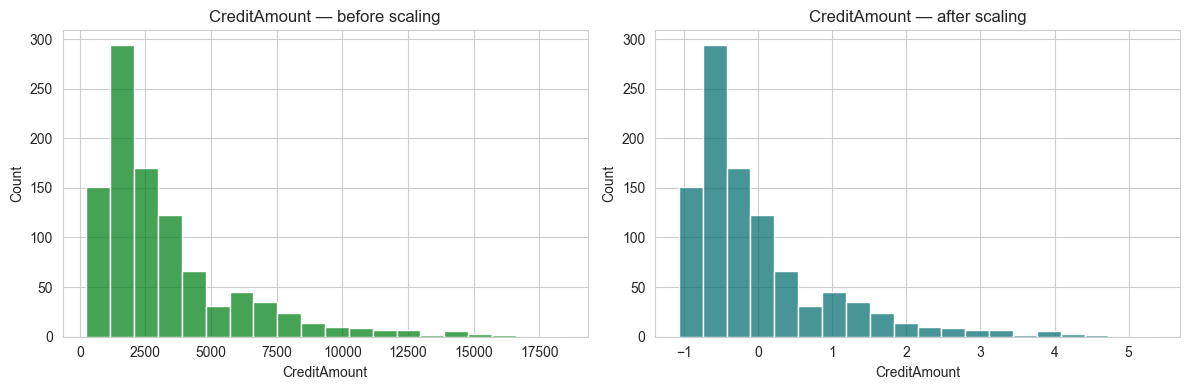

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_encoded["CreditAmount"], bins=20, ax=axes[0], color="#08831C")
axes[0].set_title("CreditAmount — before scaling")
sns.histplot(df_scaled["CreditAmount"], bins=20, ax=axes[1], color="#0A7275")
axes[1].set_title("CreditAmount — after scaling")
plt.tight_layout()
plt.show()

### 4.3 Feature selection

### Step — Feature Selection Scores

This code separates the features from the Risk column and uses SelectKBest to calculate a score for each feature. The scores help us identify which features are more useful for distinguishing between good and bad credit risk. The results are sorted from highest to lowest score.

In [ ]:
X = df_scaled.drop(columns=["Risk"])
y = df_scaled["Risk"]

selector = SelectKBest(score_func=f_classif, k="all")
selector.fit(X, y)

feature_scores = pd.DataFrame({
    "Feature": X.columns,
    "Score": selector.scores_
}).sort_values("Score", ascending=False).reset_index(drop=True)

feature_scores

,Feature,Score
0,CheckingAccount,111.721482
1,Duration,48.333790
2,SavingAccounts,33.948465
3,CreditAmount,24.482366
4,Age,8.356995
5,Sex,5.720350
6,Purpose,3.745234
7,Job,1.070584
8,Housing,0.372463


### Figure — Feature Scores

This code creates a bar chart showing the scores of each feature. Features with higher scores may be more useful for distinguishing between good and bad credit risk.

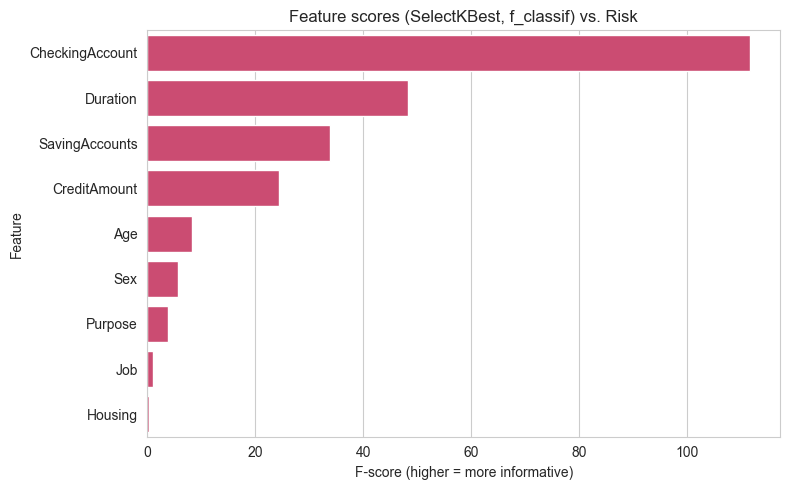

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(data=feature_scores, x="Score", y="Feature", color="#E0376A")
plt.title("Feature scores (SelectKBest, f_classif) vs. Risk")
plt.xlabel("F-score (higher = more informative)")
plt.tight_layout()
plt.show()